# Welcome to SMS Spam Detection!

In [1]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

file_path = project_folder / "data" / "spam_messages_train.csv"

train_df = pd.read_csv(file_path)

In [2]:
train_df.head()

,label,text
0,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
1,ham,I sent my scores to sophas and i had to do sec...
2,spam,We know someone who you know that fancies you....
3,ham,Only if you promise your getting out as SOON a...
4,spam,Congratulations ur awarded either �500 of CD g...


In [3]:
shape = train_df.shape
print(f"total rows: {shape[0]}")
print(f"total columns: {shape[1]}")

total rows: 47392
total columns: 2


In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47392 entries, 0 to 47391
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   47392 non-null  str  
 1   text    47392 non-null  str  
dtypes: str(2)
memory usage: 740.6 KB


In [5]:
train_df["label"].value_counts()

label
ham     28560
spam    18832
Name: count, dtype: int64

## checking the nulll values

In [6]:
train_df.isnull().sum()

label    0
text     0
dtype: int64

## checking the duplicates 

In [7]:
train_df.duplicated().sum()

np.int64(2823)

## checking the empty messages such as white spaces 

In [8]:
train_df["text"].str.strip().eq("").sum()

np.int64(0)

## checking duplicate records 

In [9]:
duplicates = train_df[
    train_df.duplicated(keep=False)
]

duplicates.head(10)

,label,text
7,ham,No message..no responce..what happend?
50,spam,HMV BONUS SPECIAL 500 pounds of genuine HMV vo...
51,ham,He remains a bro amongst bros
61,spam,Buy Space Invaders 4 a chance 2 win orig Arcad...
66,ham,As per your request 'Maangalyam (Alaipayuthe)'...
73,ham,Honeybee Said: *I'm d Sweetest in d World* God...
75,spam,WINNER!! As a valued network customer you have...
79,ham,Sad story of a Man - Last week was my b'day. M...
94,ham,"Sorry, I'll call later"
102,ham,Wat r u doing?


In [10]:
label_counts = train_df.groupby("text")["label"].nunique()

conflicting_messages = label_counts[label_counts > 1]

print("Messages with conflicting labels:", len(conflicting_messages))

Messages with conflicting labels: 1


In [11]:
train_df["text"].value_counts().head(10)

text
click here to be removed                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

In [12]:
val_df = pd.read_csv(
    project_folder / "data" / "spam_messages_val.csv"
)

test_df = pd.read_csv(
    project_folder / "data" / "spam_messages_test.csv"
)

In [13]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (47392, 2)
Validation: (5923, 2)
Testing: (5926, 2)


In [14]:
train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

common_messages = train_texts.intersection(test_texts)

print("Messages shared between train and test:", len(common_messages))

Messages shared between train and test: 624


In [15]:
train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print("Train vs Validation:",
      len(train_texts.intersection(val_texts)))

print("Train vs Test:",
      len(train_texts.intersection(test_texts)))

print("Validation vs Test:",
      len(val_texts.intersection(test_texts)))

Train vs Validation: 643
Train vs Test: 624
Validation vs Test: 99


In [16]:
# Create independent copies
train_clean = train_df.copy()
val_clean = val_df.copy()
test_clean = test_df.copy()

# Keep the test split as the reference
test_texts = set(test_clean["text"])

# Remove test messages from validation
val_clean = val_clean[
    ~val_clean["text"].isin(test_texts)
].copy()

# Remove validation and test messages from training
reserved_texts = set(val_clean["text"]) | test_texts

train_clean = train_clean[
    ~train_clean["text"].isin(reserved_texts)
].copy()

In [17]:
train_clean = train_clean.drop_duplicates().reset_index(drop=True)

val_clean = val_clean.drop_duplicates().reset_index(drop=True)

test_clean = test_clean.drop_duplicates().reset_index(drop=True)

In [18]:
print("Train:", train_clean.shape)
print("Validation:", val_clean.shape)
print("Test:", test_clean.shape)

print(
    "Train vs Validation:",
    len(set(train_clean["text"]) & set(val_clean["text"]))
)

print(
    "Train vs Test:",
    len(set(train_clean["text"]) & set(test_clean["text"]))
)

print(
    "Validation vs Test:",
    len(set(val_clean["text"]) & set(test_clean["text"]))
)

Train: (43321, 2)
Validation: (5755, 2)
Test: (5887, 2)
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


In [19]:
conflicts = train_clean.groupby("text")["label"].nunique()

print("Conflicting texts:", (conflicts > 1).sum())

Conflicting texts: 1


In [20]:
conflicts = train_clean.groupby("text")["label"].nunique()

conflicting_texts = conflicts[conflicts > 1].index

train_clean[train_clean["text"].isin(conflicting_texts)]

,label,text
21865,spam,hi
37796,ham,hi


In [22]:
train_clean = train_clean[
    ~train_clean["text"].isin(conflicting_texts)
].reset_index(drop=True)

In [23]:
print("Training rows:", len(train_clean))

conflicts = train_clean.groupby("text")["label"].nunique()

print("Conflicting texts:", (conflicts > 1).sum())

Training rows: 43319
Conflicting texts: 0


In [24]:
train_clean["label"].value_counts()

label
ham     27319
spam    16000
Name: count, dtype: int64

In [25]:
train_clean["label"].value_counts(normalize=True) * 100

label
ham     63.064706
spam    36.935294
Name: proportion, dtype: float64

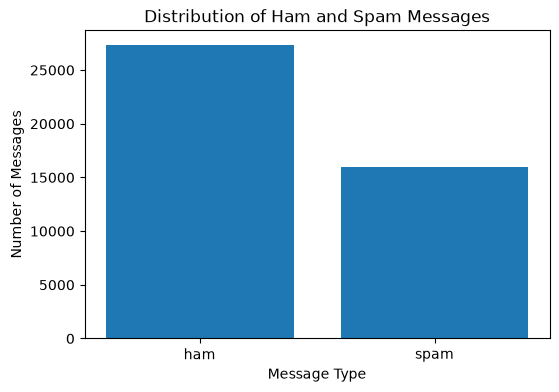

In [26]:
import matplotlib.pyplot as plt

label_counts = train_clean["label"].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(label_counts.index, label_counts.values)

plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.title("Distribution of Ham and Spam Messages")

plt.show()

## Message Length Analysis

We calculate the number of characters in each message
to investigate whether spam and ham messages have
different length patterns.

In [27]:
train_clean["message_length"] = train_clean["text"].str.len()

train_clean[["label", "text", "message_length"]].head()

,label,text,message_length
0,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t...",151
1,ham,I sent my scores to sophas and i had to do sec...,221
2,spam,We know someone who you know that fancies you....,101
3,ham,Only if you promise your getting out as SOON a...,124
4,spam,Congratulations ur awarded either �500 of CD g...,148


In [28]:
train_clean.groupby("label")["message_length"].mean()

label
ham     839.941616
spam    970.128687
Name: message_length, dtype: float64

In [29]:
train_clean.groupby("label")["message_length"].agg(
    ["min", "max", "mean", "median"]
)

,min,max,mean,median
label,,,,
ham,1,228353,839.941616,329.0
spam,2,28688,970.128687,442.0
